**Deployment URL:** PENDING - replace with the verified public app URL after deployment.

# Titanic Passenger Survival Prediction System


Course: AIC354 Machine Learning Fundamentals — Assignment 2

This notebook follows the instructor repository's structure: load data, understand/preprocess it, label-encode categorical attributes, train an SVC, test it with multiple metrics, try a user prediction, and save the trained model for cloud deployment.

**Important data note:** this assignment starter uses the instructor repository's 100-row `sample-data.csv`, not the full historical Titanic passenger manifest. Treat results as a teaching exercise rather than a historically reliable survival model.

Starter repository: https://github.com/haqnawaz99/ml-teaching-notebooks

## Step 1 — Import libraries

In [1]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Make paths work whether Jupyter is started from the project folder or notebooks/.
CURRENT_DIR = Path.cwd()
BASE_DIR = CURRENT_DIR if (CURRENT_DIR / "data").exists() else CURRENT_DIR.parent
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
MODEL_PATH = BASE_DIR / "titanic_model.pkl"

## Step 2 — Load sample data

In [2]:
DATA_PATH = DATA_DIR / "sample-data.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected dataset at {DATA_PATH}. Keep the data/ folder beside the project files.")

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (100, 5)


,PClass,Gender,Sibling,Embarked,Survived
0,Third,Male,One,Southampton,No
1,Second,Female,Zero,Southampton,Yes
2,Third,Male,Zero,Southampton,No
3,Third,Female,Three,Southampton,Yes
4,Third,Male,Zero,Queenstown,No
5,First,Female,Three,Southampton,Yes
6,Third,Male,Zero,Southampton,No
7,Third,Male,Zero,Southampton,Yes
8,First,Male,Zero,Southampton,No
9,Second,Male,Zero,Southampton,Yes


## Step 3 — Understand and preprocess the data

The four input attributes are `PClass`, `Gender`, `Sibling`, and `Embarked`. The target is `Survived`. Check types, missing values, duplicates, and class balance before training.

In [3]:
print("Column types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["Survived"].value_counts())

Column types:
PClass      str
Gender      str
Sibling     str
Embarked    str
Survived    str
dtype: object

Missing values:
PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0
dtype: int64

Duplicate rows: 55

Target distribution:


Survived
No     50
Yes    50
Name: count, dtype: int64

In [4]:
# Keep only the four required inputs and target; drop incomplete records and duplicates.
feature_columns = ["PClass", "Gender", "Sibling", "Embarked"]
target_column = "Survived"
data = df[feature_columns + [target_column]].dropna().drop_duplicates().copy()

# Standardize text values and inspect cleaned data.
for column in feature_columns + [target_column]:
    data[column] = data[column].astype(str).str.strip()

print("Rows after preprocessing:", len(data))
display(data.head())

Rows after preprocessing: 45


,PClass,Gender,Sibling,Embarked,Survived
0,Third,Male,One,Southampton,No
1,Second,Female,Zero,Southampton,Yes
2,Third,Male,Zero,Southampton,No
3,Third,Female,Three,Southampton,Yes
4,Third,Male,Zero,Queenstown,No


## Step 4 — Feature extraction

Select exactly the four attributes specified in the instructor's example. `Survived` is the label we want the model to predict.

In [5]:
X_text = data[feature_columns].copy()
y_text = data[target_column].copy()
print("Input features:", feature_columns)
print("Target labels:", sorted(y_text.unique().tolist()))

Input features: ['PClass', 'Gender', 'Sibling', 'Embarked']
Target labels: ['No', 'Yes']


## Step 5 — Label encoding

Machine-learning estimators need numeric inputs. Fit one `LabelEncoder` per categorical input and another encoder for the output label. These fitted encoders are saved alongside the model so the live app uses the same mappings.

In [6]:
feature_encoders = {}
X = X_text.copy()
for column in feature_columns:
    encoder = LabelEncoder()
    X[column] = encoder.fit_transform(X_text[column])
    feature_encoders[column] = encoder

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)

print("Encoded feature sample:")
display(X.head())
print("Target mapping:", {label: int(target_encoder.transform([label])[0]) for label in target_encoder.classes_})

Encoded feature sample:


,PClass,Gender,Sibling,Embarked
0,2,1,0,2
1,1,0,3,2
2,2,1,3,2
3,2,0,1,2
4,2,1,3,1


Target mapping: {'No': 0, 'Yes': 1}


## Step 6 — Training phase

Split the data into training and testing subsets. The test set is held aside until evaluation. Train the Support Vector Classifier (SVC), which follows the instructor notebook's approach.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

model = SVC(gamma="auto", random_state=0)
model.fit(X_train, y_train)
print("Training complete.")

Training records: 36
Testing records: 9
Training complete.


In [8]:
# Save the full prediction bundle, including encoders and ordered feature names.
model_bundle = {
    "model": model,
    "feature_columns": feature_columns,
    "feature_encoders": feature_encoders,
    "target_encoder": target_encoder,
    "categorical_features": feature_columns,
    "dataset_file": "data/sample-data.csv",
}
with open(MODEL_PATH, "wb") as file:
    pickle.dump(model_bundle, file)
print("Saved trained model bundle to:", MODEL_PATH)

Saved trained model bundle to: [project folder]\titanic_model.pkl


## Step 7 — Testing and evaluation

Accuracy alone can hide class-specific mistakes, so also report precision, recall, F1-score, and the confusion matrix.

In [9]:
y_pred = model.predict(X_test)
positive_label = int(target_encoder.transform(["Yes"])[0])
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision (survived=Yes): {precision_score(y_test, y_pred, pos_label=positive_label, zero_division=0):.3f}")
print(f"Recall (survived=Yes):    {recall_score(y_test, y_pred, pos_label=positive_label, zero_division=0):.3f}")
print(f"F1-score (survived=Yes):  {f1_score(y_test, y_pred, pos_label=positive_label, zero_division=0):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=target_encoder.classes_, zero_division=0))

Accuracy:  0.333
Precision (survived=Yes): 0.250
Recall (survived=Yes):    0.250
F1-score (survived=Yes):  0.250

Classification report:
              precision    recall  f1-score   support

          No       0.40      0.40      0.40         5
         Yes       0.25      0.25      0.25         4

    accuracy                           0.33         9
   macro avg       0.33      0.33      0.33         9
weighted avg       0.33      0.33      0.33         9



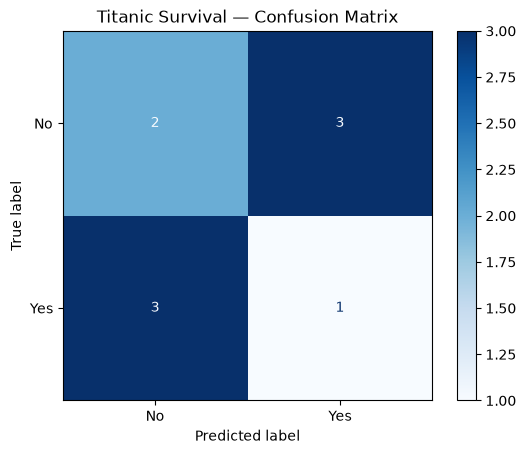

In [10]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_encoder.classes_)
display.plot(cmap="Blues", values_format="d")
plt.title("Titanic Survival — Confusion Matrix")
plt.show()

## Step 8 — Application phase: predict for a new passenger

Change the example values below to test another combination. The values must be among the categories found in the training data.

In [11]:
new_passenger = {
    "PClass": "Third",
    "Gender": "Female",
    "Sibling": "Zero",
    "Embarked": "Southampton",
}

new_row = pd.DataFrame([new_passenger], columns=feature_columns)
for column in feature_columns:
    new_row[column] = feature_encoders[column].transform(new_row[column].astype(str))
prediction_code = model.predict(new_row)[0]
prediction = target_encoder.inverse_transform([prediction_code])[0]
print("Input passenger:", new_passenger)
print("Predicted survival:", prediction)

Input passenger: {'PClass': 'Third', 'Gender': 'Female', 'Sibling': 'Zero', 'Embarked': 'Southampton'}
Predicted survival: Yes


## Step 9 — Feedback and improvements

Potential improvements: collect a larger and more realistic dataset, verify data quality, compare additional classifiers, tune hyperparameters using cross-validation, and monitor model performance after deployment. Ask users/domain experts whether the inputs and output are understandable, and never present this small teaching dataset as a real-world decision tool.

## Step 10 — Deploy to Streamlit Community Cloud

1. Run all cells so `titanic_model.pkl` is created.
2. Keep `app.py`, `model_utils.py`, `requirements.txt`, `data/sample-data.csv`, and both model files in the GitHub repository root (the heart notebook creates `heart_disease_model.pkl`).
3. Push the files to a GitHub repository you own.
4. Sign in at https://share.streamlit.io/ and create an app pointing to `app.py`.
5. After the app deploys, copy its public URL into the deployment link at the top of this notebook.
6. Test both tabs on the public URL. Do not claim a deployment is complete until the link works.

The hosted app is an educational demonstration, not medical advice.